# 0-instruments: thermocouple

Measure the thermocouple's offset, slope, noise and response time on the DMM's temperature input, so the thermal experiments in stage 3 can correct its readings and know how long to wait after a change.

## Purpose

Stage 3 measures the servo case and winding temperature with a type K thermocouple read by the DMM. A thermocouple has an offset and a slope of its own, and the DMM adds its cold junction and its reading accuracy. The tip also takes time to follow a change. Two fixed points, ice water and boiling water, give the offset and slope. The dip from air into ice water and the climb back out into air give the response time in liquid and in air.

## Procedure

`capture.py` logs the DMM in temperature mode throughout and asks for a keypress at each move, which it writes as a mark. It runs in two forms.

`capture.py` runs the full sequence:

1. Thermocouple plugged in, DMM on temperature in C, Bluetooth on, tip in air. Logged for 60 s.
2. Tip into the ice bath, among the ice and off the glass. Logged for 180 s.
3. Tip into boiling water, off the pot. Logged for 180 s.
4. Tip back out into the air. Logged for 60 s.

`capture.py ice` runs the ice bath alone: air for 30 s, the ice bath for 240 s, air for 30 s.

Two captures are used here. Capture 1 is the full sequence. Its ice bath had more water than ice and did not settle at 0 C, so capture 2 repeats the ice bath alone with a packed glass. The offset comes from capture 2. The boiling point, the noise and the response times come from capture 1.

A glass packed with crushed ice, with just enough water to fill the gaps, is 0 C once the ice has warmed to its melting point. Ice straight from the freezer is well below 0 C, so the packed glass stands for about five minutes, until the ice is wet all over and melting, and gets a stir before the tip goes in. Too much water is the opposite mistake. Ice floats, so in a glass with more water than ice the water below the ice is warmer, up to about 4 C where water is densest and sinks. The tip goes in among the ice, not into the water under it. Boiling water is 100 C at standard sea level pressure and lower where the pressure is lower, by about 0.28 C per kPa. The pressure at the bench follows from its elevation and the sea level pressure in a weather report, and the boiling point from that pressure. Both are set below as `ELEVATION_M` and `SEA_LEVEL_INHG`.

## Data

Each capture folder holds two files.

- `dmm.csv`, the DMM log: `t_host`, `function` (`C`), `value` in degrees C, `raw`.
- `marks.csv`, the host time of each move: `t_host`, `mark`, with the marks `air`, `ice`, `boil` and `air2`. Capture 2 has no `boil`.

### Capture 1, dmm.csv

One row per DMM packet: `t_host`, `function` (`C` for the temperature mode), `value` in degrees C, `raw`.

bench at 223 m, 989.3 hPa, water boils at 99.29 C


,t_host,function,value,raw,t
0,02:09:57.108,C,23.500,21f20000eb00,0.000
1,02:09:57.694,C,23.500,21f20000eb00,0.585
2,02:09:58.084,C,23.400,21f20000ea00,0.975
3,02:09:58.668,C,23.400,21f20000ea00,1.560
4,02:09:59.253,C,23.400,21f20000ea00,2.145


1084 temperature rows, packet interval median 0.585 s


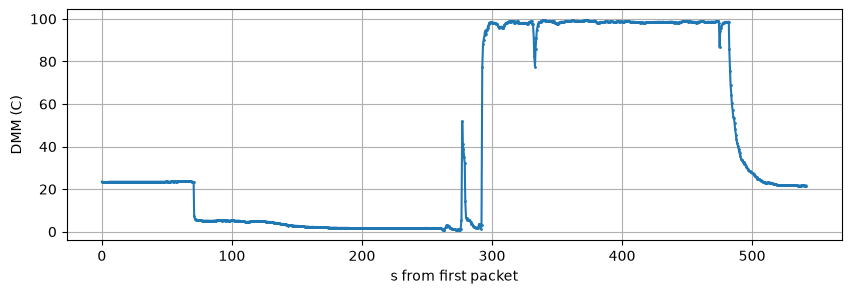

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, results, show

CAPTURE = Path("../../../telemetry/instruments/thermocouple/capture-1").resolve()
CAPTURE_ICE = Path("../../../telemetry/instruments/thermocouple/capture-2").resolve()

ELEVATION_M = 733 * 0.3048   # the bench, 733 ft
SEA_LEVEL_INHG = 30.00        # weather report's sea level pressure, about an hour after capture 1

# Pressure at the bench from the sea level report (the US National Weather Service's
# altimeter formula), then the boiling point from Clausius-Clapeyron, anchored at
# 99.974 C for 1013.25 hPa and with water's heat of vaporisation at the boil.
sea_hpa = SEA_LEVEL_INHG * 33.8639
P_BENCH_HPA = (sea_hpa ** 0.190263 - 8.417286e-5 * ELEVATION_M) ** (1 / 0.190263)
T_BOIL = 1 / (1 / 373.124 - 8.314462 * np.log(P_BENCH_HPA / 1013.25) / 40657) - 273.15
print(f"bench at {ELEVATION_M:.0f} m, {P_BENCH_HPA:.1f} hPa, water boils at {T_BOIL:.2f} C")
T_ICE = 0.0

log = b41t.load(CAPTURE / "dmm.csv")
show(log)
log = log[log.function == "C"].dropna(subset=["value"]).reset_index(drop=True)
interval = np.diff(log.t_host)
print(len(log), "temperature rows, packet interval median", f"{np.median(interval):.3f} s")
log.plot(x="t", y="value", style=".-", ms=2, figsize=(10, 3), grid=True, legend=False, ylabel="DMM (C)", xlabel="s from first packet");

The whole of capture 1 as the DMM saw it. Air, the drop into ice water, the climb into boiling water, and back out.

### Capture 1, marks.csv

The host time of each move, from the keypresses.

In [2]:
marks = pd.read_csv(CAPTURE / "marks.csv")
show(marks, n=None)

,t_host,mark
0,02:09:56.736,air
1,02:11:08.278,ice
2,02:14:49.085,boil
3,02:17:58.924,air2


### Capture 2, dmm.csv

The ice bath alone, same columns.

,t_host,function,value,raw,t
0,02:45:47.117,C,22.800,21f20000e400,0.000
1,02:45:47.506,C,22.800,21f20000e400,0.390
2,02:45:48.091,C,22.800,21f20000e400,0.974
3,02:45:48.482,C,22.800,21f20000e400,1.365
4,02:45:49.068,C,22.800,21f20000e400,1.951


628 temperature rows


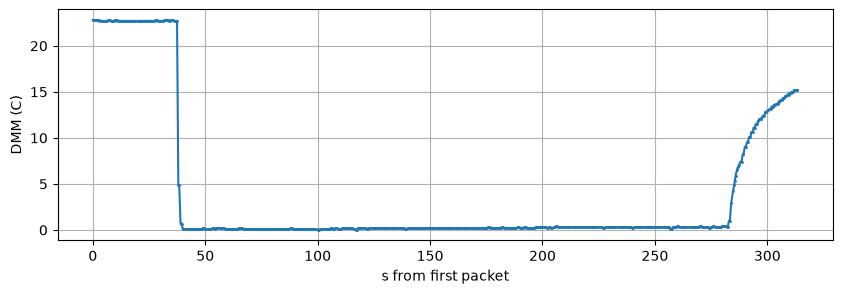

In [3]:
log_ice = b41t.load(CAPTURE_ICE / "dmm.csv")
show(log_ice)
log_ice = log_ice[log_ice.function == "C"].dropna(subset=["value"]).reset_index(drop=True)
print(len(log_ice), "temperature rows")
log_ice.plot(x="t", y="value", style=".-", ms=2, figsize=(10, 3), grid=True, legend=False, ylabel="DMM (C)", xlabel="s from first packet");

Capture 2 as the DMM saw it. Air, the drop into the packed ice, and back out.

### Capture 2, marks.csv

In [4]:
marks_ice = pd.read_csv(CAPTURE_ICE / "marks.csv")
show(marks_ice, n=None)

,t_host,mark
0,02:45:46.542,air
1,02:46:24.002,ice
2,02:50:30.713,air2


## Method

The DMM's reading is taken as $a + b\,T$ over 0 to 100 C. Each bath's reading is the median of the last 60 s the tip spent in it, and the two baths give $a$ and $b$.

The marks say when the key was pressed, and the hand is not always on time. A tip can leave a bath before the key goes down, or touch the pot for a moment. So the reading of a bath is taken from the flattest 60 s the tip spent in it, the window of least spread between one mark and the next, and that window is shown on the plot. The DMM's own first departure from the air reading, not the keypress, is time zero for the response time.

The offset is the reading in capture 2's packed ice bath, which sits at 0 C. Its value is the median of the first 60 s after the reading settles, when the bath was freshest. The lowest reading and the median of the last 60 s bound it. The slope is then the boiling reading of capture 1 less the offset, over the boiling point.

Capture 1's ice bath gives a cross-check. Water in contact with ice cannot be colder than 0 C, and ice that has sat in water for minutes is at 0 C at its surface, even if its core is still colder. In this run the ice had been in plenty of water for minutes before the tip went in. So whatever the bath did, the lowest reading the tip gave in it is an upper bound on the offset at 0 C.

The tip follows a step as a first order lag. If the reading has covered a fraction $f$ of the step by the first packet after departure, one packet interval $\Delta t$ apart, the time constant is at most $\Delta t / \ln(1/(1-f))$. The dip into the ice water gives that bound for a liquid. The climb back into the air after the boil gives the time to come within 1 C of the final air reading, which is the slower case the thermal stage will meet.

### The plateaus

The log cut into segments at the marks, and the flattest 60 s window of each. The last air segment is only 60 s long and starts with the climb out of the water, so its window is 20 s.

air 23.50 C (sd 0.04), air again 21.80 C (sd 0.08)
ice 1.70 C (sd 0.05, drift -0.03 C/min); in the ice water the reading ran from 7.2 down to 1.6 C over 190 s
boil 98.60 C (sd 0.17, drift +0.26 C/min)
lowest reading in the ice segment 0.8 C, so the offset at 0 C is at most that
boiling reading -0.69 C from 99.29 C, the boiling point at the bench


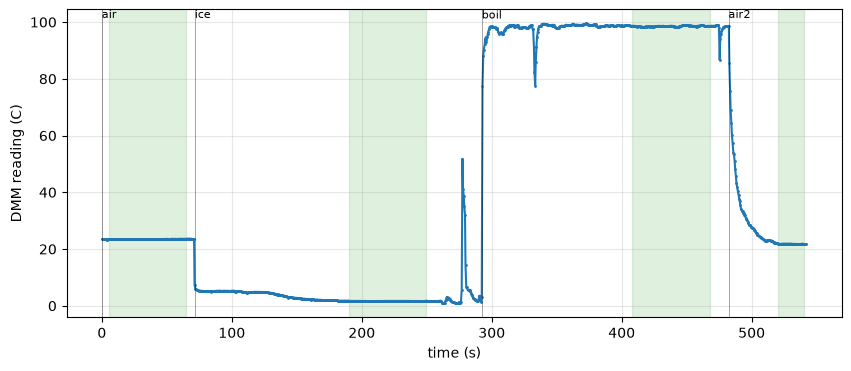

In [5]:
mark_t = marks.set_index("mark").t_host
ends = dict(zip(marks["mark"], list(marks.t_host.iloc[1:]) + [log.t_host.iloc[-1] + 1]))

def segment(name):
    return log[(log.t_host >= mark_t[name] - 2.0) & (log.t_host < ends[name])]

def flattest(s, window_s=60):
    best = None
    for t0 in s.t_host:
        w = s[(s.t_host >= t0) & (s.t_host < t0 + window_s)]
        if w.t_host.iloc[-1] - t0 < window_s - 2 * np.median(interval):
            break
        if best is None or w.value.std() < best.value.std():
            best = w
    return best

def plateau(w):
    drift = np.polyfit(w.t_host - w.t_host.iloc[0], w.value, 1)[0] * 60
    return float(w.value.median()), float(w.value.std()), float(drift)

windows = {name: flattest(segment(name)) for name in ("air", "ice", "boil")}
windows["air2"] = flattest(segment("air2"), window_s=20)
air, air_sd, _ = plateau(windows["air"])
ice, ice_sd, ice_slope = plateau(windows["ice"])
boil, boil_sd, boil_slope = plateau(windows["boil"])
air2, air2_sd, _ = plateau(windows["air2"])
ice_all = segment("ice")
ice_all = ice_all[ice_all.t_host >= ice_all.t_host[ice_all.value < air - 2.0].iloc[0]]
moved = ice_all[(ice_all.t_host > windows["ice"].t_host.iloc[-1]) & ((ice_all.value - ice).abs() > 0.5)]
if len(moved):
    ice_all = ice_all[ice_all.t_host < moved.t_host.iloc[0]]
print(f"air {air:.2f} C (sd {air_sd:.2f}), air again {air2:.2f} C (sd {air2_sd:.2f})")
print(f"ice {ice:.2f} C (sd {ice_sd:.2f}, drift {ice_slope:+.2f} C/min); in the ice water the reading ran from {ice_all.value.iloc[0]:.1f} down to {ice_all.value.min():.1f} C over {ice_all.t_host.iloc[-1] - ice_all.t_host.iloc[0]:.0f} s")
print(f"boil {boil:.2f} C (sd {boil_sd:.2f}, drift {boil_slope:+.2f} C/min)")
offset_max = float(segment("ice").value.min())
print(f"lowest reading in the ice segment {offset_max:.1f} C, so the offset at 0 C is at most that")
print(f"boiling reading {boil - T_BOIL:+.2f} C from {T_BOIL:.2f} C, the boiling point at the bench")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(log.t_host - mark_t["air"], log.value, ".-", ms=2)
for name, t in mark_t.items():
    ax.axvline(t - mark_t["air"], color="k", lw=0.5, alpha=0.5); ax.text(t - mark_t["air"], ax.get_ylim()[1], name, va="top", fontsize=8)
for name, w in windows.items():
    ax.axvspan(w.t_host.iloc[0] - mark_t["air"], w.t_host.iloc[-1] - mark_t["air"], color="tab:green", alpha=0.15)
ax.set_xlabel("time (s)"); ax.set_ylabel("DMM reading (C)"); ax.grid(alpha=0.3)
plt.show()

The run with a line at each keypress and the flattest 60 s of each segment shaded. A bath should be flat to a few tenths of a degree over its window. A drift there means the bath itself was still changing, and its reading is then the bath's temperature, not the thermocouple's offset. The spike to 50 C near the end of the ice segment is the tip going into the boiling water and straight back into the ice before the key was pressed. The window of least spread leaves it out.

The boiling water in capture 1 was about 13 mm deep, in a small pot on an induction stove at full power, with the tip held off the bottom by hand. Between about 60 and 100 s into the boil the reading rose to 99.5 C. The tip had gone deeper there, close to or touching the bottom, which runs hotter than the boiling point on a strong burner, and it was pulled back up once the rise was seen. The flattest minute comes from later in the segment, with the tip off the bottom.

### Capture 1's ice bath on its own

The ice segment of capture 1 alone, from the tip's entry until the reading first moves more than 0.5 C off the settled level after the flattest minute. That cut leaves out the end of the segment, where the tip was moved about in the glass, dipped into the boiling water and put back before the key was pressed.

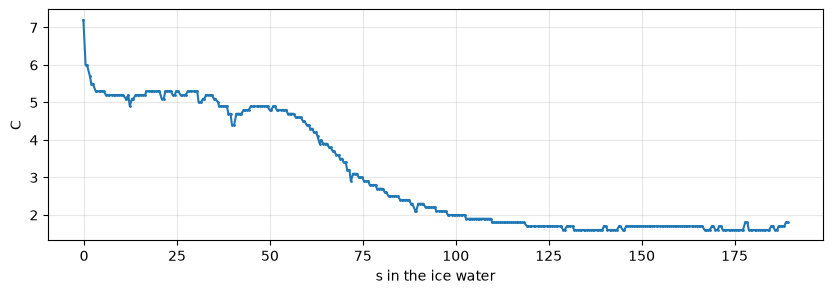

In [6]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(ice_all.t_host - mark_t["ice"], ice_all.value, ".-", ms=2)
ax.set_xlabel("s in the ice water"); ax.set_ylabel("C"); ax.grid(alpha=0.3)
plt.show()

The reading in the ice water while the tip sat still. The bath was stirred before the run and not during it, since stirring moves the tip. For the first 50 s the tip sat deep in the glass, under the floating ice, and read about 5.2 C. That is the water under the ice, which settles toward 4 C, where water is densest. The tip was then raised into the ice layer, and the reading fell over about a minute to 1.7 C and stayed there. Without stirring, the water around the tip in the ice layer was most likely still a little above 0 C. In the seconds cut off at the end, the reading touched 0.8 C as the tip was moved about. That points the same way, with moderate confidence. The water right against the ice was colder than where the tip sat.

### The ice point

Capture 2's ice segment, from 5 s after the tip went in until it came out. The exit is the first jump of more than 0.5 C between two packets after the first 30 s. Inside the bath the reading moves in steps of 0.1 or 0.2 C.

packed ice: first minute 0.10 C, last minute 0.30 C, lowest 0.00 C, drift +0.062 C/min over 239 s
capture 1's bound 0.8 C; the offset is inside it
reading = +0.10 + 0.9920 x T, with the boiling point at 99.29 C


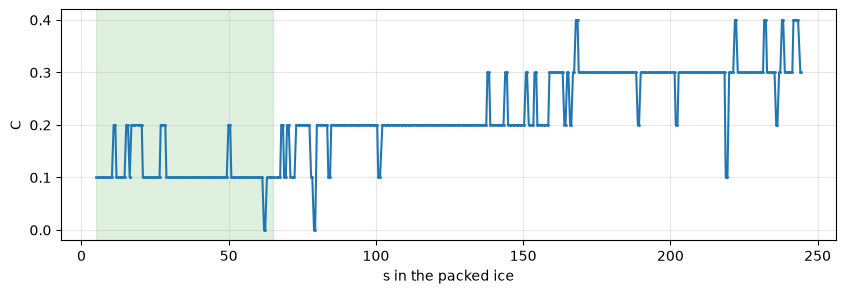

In [7]:
mi = marks_ice.set_index("mark").t_host
air_ice = float(log_ice.value[log_ice.t_host < mi["ice"]].median())
s2 = log_ice[(log_ice.t_host >= mi["ice"] - 2.0) & (log_ice.t_host < mi["air2"] + 5.0)]
t_in = s2.t_host[s2.value < air_ice - 2.0].iloc[0]
s2 = s2[s2.t_host >= t_in + 5.0]
out_jump = s2[(s2.value.diff().abs() > 0.5) & (s2.t_host > s2.t_host.iloc[0] + 30)]
if len(out_jump):
    s2 = s2[s2.t_host < out_jump.t_host.iloc[0]]
first60 = s2[s2.t_host < s2.t_host.iloc[0] + 60]
last60 = s2[s2.t_host >= s2.t_host.iloc[-1] - 60]
offset = float(first60.value.median())
offset_lo, offset_hi = float(s2.value.min()), float(last60.value.median())
ice_drift = float(np.polyfit(s2.t_host - s2.t_host.iloc[0], s2.value, 1)[0] * 60)
slope = (boil - offset) / (T_BOIL - T_ICE)
print(f"packed ice: first minute {offset:.2f} C, last minute {offset_hi:.2f} C, lowest {offset_lo:.2f} C, drift {ice_drift:+.3f} C/min over {s2.t_host.iloc[-1] - s2.t_host.iloc[0]:.0f} s")
print(f"capture 1's bound {offset_max:.1f} C; the offset is {'inside' if offset <= offset_max else 'OUTSIDE'} it")
print(f"reading = {offset:+.2f} + {slope:.4f} x T, with the boiling point at {T_BOIL:.2f} C")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(s2.t_host - t_in, s2.value, ".-", ms=2)
ax.axvspan(first60.t_host.iloc[0] - t_in, first60.t_host.iloc[-1] - t_in, color="tab:green", alpha=0.15)
ax.set_xlabel("s in the packed ice"); ax.set_ylabel("C"); ax.grid(alpha=0.3)
plt.show()

The packed ice bath, with the first minute shaded. The reading sat at 0.1 C, the DMM's resolution, for the first minute and crept up to 0.3 C over the next three. The creep is most likely meltwater collecting around the tip as the ice melted away from it, with moderate confidence. Heat running down the thermocouple's leads from the room would look the same. Either way the bath is closest to 0 C at the start, so the first minute gives the offset and the rest gives its upper end. Capture 1's ice bath, by its lowest reading, put the offset at no more than 0.8 C, and this agrees.

### Response time

The ice dip against the packet interval, and the cooling back into air.

into ice: 23.4 -> 7.2 C by the next packet, 91% of the step to 5.5 C; tau below 0.25 s for one packet interval
out into air: 98.6 -> 21.8 C, within 1 C after 34 s


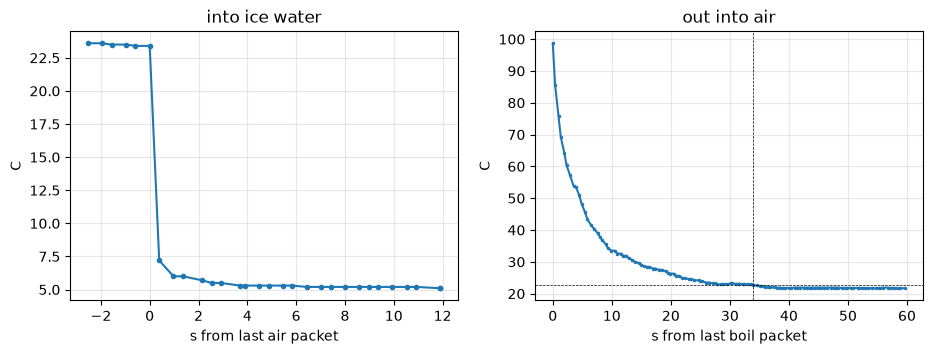

In [8]:
i_dep = ice_all.index[0]
before, first = log.loc[i_dep - 1], log.loc[i_dep]
landing = float(ice_all.value.iloc[:10].median())
frac = float((before.value - first.value) / (before.value - landing))
tau_max = float(np.median(interval) / np.log(1 / (1 - frac)))
print(f"into ice: {before.value:.1f} -> {first.value:.1f} C by the next packet, {frac:.0%} of the step to {landing:.1f} C; tau below {tau_max:.2f} s for one packet interval")

a2 = segment("air2")
i_dep = a2.index[a2.value < boil - 2.0][0]
t0 = float(log.t_host[i_dep - 1])
a2 = a2[a2.t_host >= t0]
settled = a2[(a2.value - air2).abs() <= 1.0]
t_1c = float(settled.t_host.iloc[0] - t0)
print(f"out into air: {boil:.1f} -> {air2:.1f} C, within 1 C after {t_1c:.0f} s")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
w = log[(log.t_host >= before.t_host - 3) & (log.t_host <= before.t_host + 12)]
axs[0].plot(w.t_host - before.t_host, w.value, ".-"); axs[0].set_title("into ice water"); axs[0].set_xlabel("s from last air packet")
axs[1].plot(a2.t_host - t0, a2.value, ".-", ms=3); axs[1].axhline(air2 + 1, color="k", lw=0.5, ls="--"); axs[1].axvline(t_1c, color="k", lw=0.5, ls="--")
axs[1].set_title("out into air"); axs[1].set_xlabel("s from last boil packet")
for ax in axs:
    ax.set_ylabel("C"); ax.grid(alpha=0.3)
plt.show()

Left, the drop into the ice water. The DMM reports once per packet, and the reading is most of the way down by the first one, so the tip in liquid is faster than the DMM can show. Right, the climb out of the boiling water into still air, with the time to come within 1 C of the final reading marked.

## Results

The offset from capture 2, the boiling reading and the slope from capture 1 with that offset, the noise in still air, and the two response times go into the result. The slope's range follows from the offset's range. The slope also depends on the boiling point, which rests on `ELEVATION_M` and `SEA_LEVEL_INHG`.

In [9]:
results.write("0-instruments", "thermocouple", CAPTURE,
              notes=f"offset from capture-2 (packed ice), the rest from capture-1; boiling point {T_BOIL:.2f} C at {P_BENCH_HPA:.1f} hPa ({ELEVATION_M:.0f} m, {SEA_LEVEL_INHG:.2f} inHg at sea level); DMM temperature accuracy from the manual: to add",
              offset_c=results.quantity(offset, offset_lo, offset_hi, "C"),
              boil_reading_c=results.quantity(boil, boil - 2 * boil_sd, boil + 2 * boil_sd, "C"),
              slope=results.quantity(slope, (boil - offset_hi) / T_BOIL, (boil - offset_lo) / T_BOIL, "C/C"),
              noise_sd_c=results.quantity(air_sd, unit="C"),
              tau_liquid_max_s=results.quantity(tau_max, unit="s"),
              settle_air_1c_s=results.quantity(t_1c, unit="s"),
              packet_interval_s=results.quantity(float(np.median(interval)), unit="s"))

PosixPath('/home/aaron/projects/OpenServoCore/notebooks/stages/0-instruments/thermocouple/results.json')

## Limitations

- Capture 1's ice bath had more water than ice and was not stirred during the run. The tip read the water under the ice first and the ice layer later, and neither settled at 0 C. It serves only as a cross-check.
- Capture 2's packed bath crept from 0.1 to 0.3 C over four minutes. The offset is taken from its first minute, and the creep sets the upper end of its range. The DMM shows tenths of a degree, so the offset is known to about 0.1 C at best.
- Capture 1's boiling water was only about 13 mm deep. In that depth the tip is never far from the surface, which evaporation keeps a little below the boiling point, nor from the bottom, which the burner keeps a little above it, and most of the thermocouple's wire sits above the water, where it draws heat from the tip. The reading moved by about a degree with the tip's position. The boiling reading is therefore as much a property of the bath as of the thermocouple, and the slope taken from it is an upper estimate of the slope error.
- The offset and the boiling reading come from two captures 30 minutes apart, with the same tip and the same DMM. A drift of the DMM's cold junction between them would enter the slope.
- The pressure at the bench comes from a weather report's sea level pressure and the bench's elevation, read about an hour after capture 1, not from a barometer at the pot. The weather rarely moves the pressure by more than a few tenths of a kPa in an hour, which is under 0.1 C of boiling point. A 30 m error in the elevation moves it by another 0.1 C.
- The DMM's own temperature accuracy comes from its manual and is the floor under everything here.
- Two fixed points fix a straight line. Type K is close to linear over 0 to 100 C, and the servo stays inside that range.
- The response time in liquid is below the DMM's packet interval, so the bound is set by the meter, not the tip. The time in air is for a wet tip cooling from 100 C, and evaporation from the tip makes it read low for a while. The figure is a guide, not a constant.

## Open questions

- The slope. A run of the boiling water alone, at least 5 cm deep, with the tip at mid-depth, a few centimetres of wire under water and the tip clipped still, would show whether the 0.7 C at the boil belongs to the thermocouple or to the shallow bath. It is not planned, since the accuracy here is already enough for stage 3 (see the conclusion). It becomes worth doing only if a later result depends on absolute temperature to better than about half a degree.
- Whether the DMM's temperature mode samples slower than its volts mode. The packet interval printed above against the dmm experiment's value is the first check.

## Conclusion

At 0 C the thermocouple reads 0.1 C high, within 0.0 to 0.3 C. At the boil it reads 98.6 C, against 99.3 C expected at the bench's elevation and the day's pressure. The weather and the elevation together account for under 0.2 C of that. The rest is the thermocouple and the DMM, the shallow boiling bath, or both. The water was only about 13 mm deep, and in that depth the reading moved by a degree with the tip's position. Taken at face value, the slope is about 0.8 % low and a reading near 60 C about 0.4 C low. That is an upper estimate of the error, and it is inside the tolerance of standard type K wire.

The thermocouple and the DMM together read steady to 0.1 C, the DMM's resolution, over a minute in still air. The tip in water follows a change faster than the DMM reports, one packet every 0.585 s. In still air it takes about half a minute to settle within 1 C, and it would take longer against a dry surface than this run shows for a wet tip.

For stage 3 this means three things. Differences and trends can be trusted to a few tenths of a degree. Absolute readings over 0 to 100 C are within about 0.5 C without any correction. And a reading taken in air is only good once about 30 s have passed since the last change at the tip.

That accuracy is enough for what stage 3 does with the thermocouple, so the calibration stops here and the deeper boiling bath is not run. Stage 3 works mostly with temperature rises. The offset cancels out of a difference, and a slope error of at most 0.8 % changes a 40 C rise by about 0.3 C. Checking the winding temperature from its resistance needs a reference temperature, and half a degree there moves the check by half a degree, below what it resolves. Safety limits sit tens of degrees above normal running. The errors that will matter in stage 3 come from how the thermocouple is used, not from its calibration. A tip on the case reads the case surface, not the winding, and the gap can be several degrees under load. A tip resting on a surface in air reads low unless it is pressed into good contact. And a reading taken sooner than about 30 s after a change in air is off by more than the whole calibration. Stage 3 has to plan around those three.